# Delivery Delays and Customer Satisfaction
Brazilian E-Commerce Public Dataset by Olist

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Stage 1: Data understanding and cleaning

In [2]:
orders = pd.read_csv('olist_orders_dataset.csv')
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [3]:
orders.shape

(99441, 8)

In [4]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [5]:
orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [6]:
orders['order_status'].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [7]:
bos = orders[orders['order_delivered_customer_date'].isnull()]
bos['order_status'].value_counts() 

##8 orders have status “delivered” but no delivery date -- removed as data errors.

order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

In [8]:
orders.duplicated().sum()

np.int64(0)

In [9]:
orders['order_id'].duplicated().sum()

np.int64(0)

In [10]:
delivered = orders[
    (orders['order_status'] == 'delivered') &
    (orders['order_delivered_customer_date'].notnull())
].copy()

tarix_sutunlari = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
for sutun in tarix_sutunlari:
    delivered[sutun] = pd.to_datetime(delivered[sutun])

delivered['delay_days'] = (
    delivered['order_delivered_customer_date'] -
    delivered['order_estimated_delivery_date']
).dt.days
delivered['is_late'] = delivered['delay_days'] > 0

print(delivered.shape)

(96470, 10)


## Stage 2: Exploratory analysis of delivery delay

In [11]:
delivered['delay_days'].describe()

count    96470.000000
mean       -11.875889
std         10.182105
min       -147.000000
25%        -17.000000
50%        -12.000000
75%         -7.000000
max        188.000000
Name: delay_days, dtype: float64

In [12]:
delivered['is_late'].mean()

np.float64(0.06773090079817559)

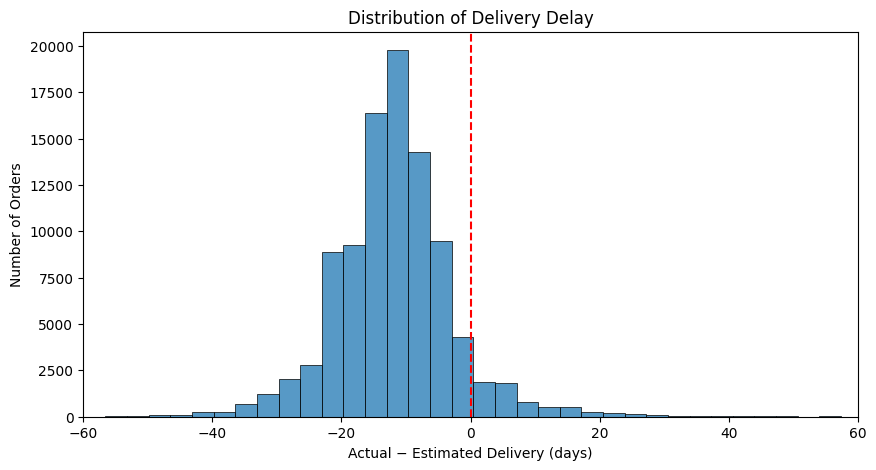

In [13]:
plt.figure(figsize=(10, 5))
sns.histplot(delivered['delay_days'], bins=100)
plt.axvline(0, color='red', linestyle='--')
plt.xlim(-60, 60)
plt.title('Distribution of Delivery Delay')
plt.xlabel('Actual − Estimated Delivery (days)')
plt.ylabel('Number of Orders')
plt.show()

In [14]:
delivered.sort_values('delay_days', ascending=False).head(10)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delay_days,is_late
55619,1b3190b2dfa9d789e1f14c05b647a14a,d306426abe5fca15e54b645e4462dc7b,delivered,2018-02-23 14:57:35,2018-02-23 15:16:14,2018-02-26 18:49:07,2018-09-19 23:24:07,2018-03-15,188,True
19590,ca07593549f1816d26a572e06dc1eab6,75683a92331068e2d281b11a7866ba44,delivered,2017-02-21 23:31:27,2017-02-23 02:35:15,2017-03-08 13:47:46,2017-09-19 14:36:39,2017-03-22,181,True
11399,47b40429ed8cce3aee9199792275433f,cb2caaaead400c97350c37a3fc536867,delivered,2018-01-03 09:44:01,2018-01-03 10:31:15,2018-02-06 01:48:28,2018-07-13 20:51:31,2018-01-19,175,True
81401,2fe324febf907e3ea3f2aa9650869fa5,65b14237885b3972ebec28c0f7dd2220,delivered,2017-03-13 20:17:10,2017-03-13 20:17:10,2017-03-17 07:23:53,2017-09-19 17:00:07,2017-04-05,167,True
89130,285ab9426d6982034523a855f55a885e,9cf2c3fa2632cee748e1a59ca9d09b21,delivered,2017-03-08 22:47:40,2017-03-08 22:47:40,2017-03-09 08:53:20,2017-09-19 14:00:04,2017-04-06,166,True
61610,440d0d17af552815d15a9e41abe49359,7815125148cfa1e8c7fee1ff7974f16c,delivered,2017-03-07 23:59:51,2017-03-09 01:11:33,2017-03-15 13:00:08,2017-09-19 15:12:50,2017-04-07,165,True
68769,c27815f7e3dd0b926b58552628481575,f85e9ec0719b16dc4dd0edd438793553,delivered,2017-03-15 23:23:17,2017-03-15 23:23:17,2017-03-21 14:50:25,2017-09-19 17:14:25,2017-04-10,162,True
38509,0f4519c5f1c541ddec9f21b3bddd533a,1a8a4a30dc296976717f44e7801fdeef,delivered,2017-03-09 13:26:57,2017-03-09 13:26:57,2017-03-22 05:28:14,2017-09-19 14:38:21,2017-04-11,161,True
40847,d24e8541128cea179a11a65176e0a96f,beeda72b31be3b8a38b5c2b77d7705c4,delivered,2017-06-12 13:14:11,2017-06-12 13:25:11,2017-06-16 14:44:37,2017-12-04 18:36:29,2017-06-26,161,True
54480,2d7561026d542c8dbd8f0daeadf67a43,8199345f57c6d1cbe9701f92481beb8d,delivered,2017-03-15 11:24:27,2017-03-15 11:24:27,2017-03-16 09:29:16,2017-09-19 14:38:18,2017-04-13,159,True


In [15]:
delivered['purchase_month'] = delivered['order_purchase_timestamp'].dt.to_period('M')

monthly = delivered.groupby('purchase_month').agg(
    n_orders=('order_id', 'count'),
    late_rate=('is_late', 'mean')
)
monthly

,n_orders,late_rate
purchase_month,,
2016-09,1,1.000000
2016-10,265,0.007547
2016-12,1,0.000000
2017-01,750,0.029333
2017-02,1653,0.029643
2017-03,2546,0.045562
2017-04,2303,0.065567
2017-05,3545,0.029901
2017-06,3135,0.030303


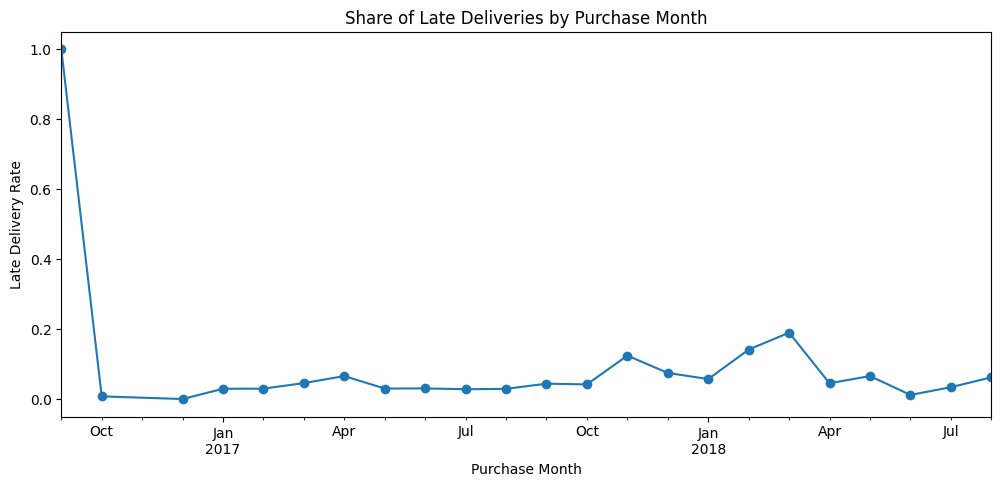

In [16]:
monthly['late_rate'].plot(figsize=(12, 5), marker='o')
plt.title('Share of Late Deliveries by Purchase Month')
plt.xlabel('Purchase Month')
plt.ylabel('Late Delivery Rate')
plt.show()

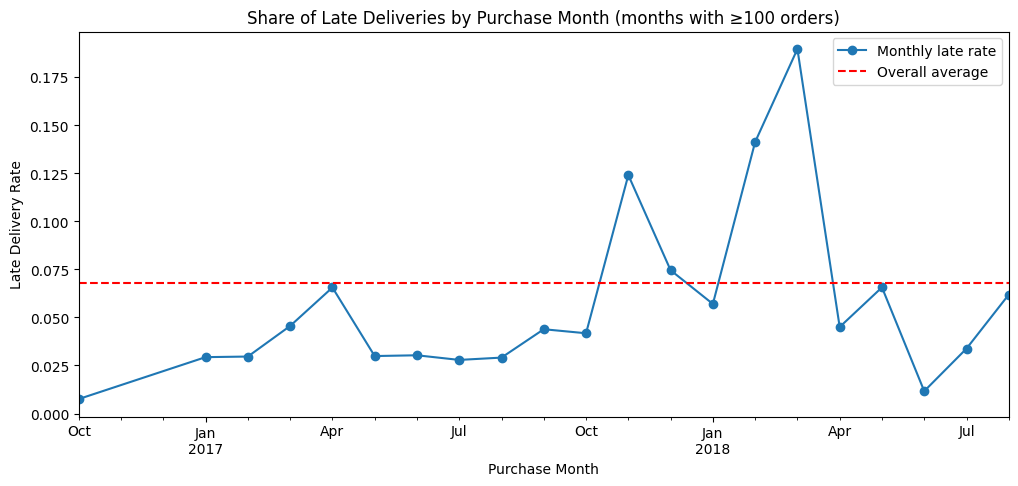

In [17]:
monthly_filtered = monthly[monthly['n_orders'] >= 100]

monthly_filtered['late_rate'].plot(figsize=(12, 5), marker='o', label='Monthly late rate')
plt.axhline(delivered['is_late'].mean(), color='red', linestyle='--', label='Overall average')
plt.title('Share of Late Deliveries by Purchase Month (months with ≥100 orders)')
plt.xlabel('Purchase Month')
plt.ylabel('Late Delivery Rate')
plt.legend()
plt.show()

## Key findings: delivery performance
- ~96.5k delivered orders analysed; 8 removed (status "delivered" but no delivery date).
- Olist estimates are conservative: the median order arrives 12 days *before* the estimate.
- Only 6.8% of orders are late, but delays have a long right tail (up to 188 days).
- Late-delivery rate spikes in Nov 2017 (Black Friday) and Feb–Mar 2018 (up to 19%).
- Limitation: recent orders not yet delivered are excluded (right-censoring),
  so late rates in the final months may be underestimated.

## Stage 2b: Delivery delay and review scores

In [18]:
reviews = pd.read_csv('olist_order_reviews_dataset.csv')

print(reviews.shape)
reviews.head()

(99224, 7)


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [19]:
print('Təkrarlanan order_id:', reviews['order_id'].duplicated().sum())
print('Təkrarlanan review_id:', reviews['review_id'].duplicated().sum())

Təkrarlanan order_id: 551
Təkrarlanan review_id: 814


In [20]:
reviews['review_score'].value_counts().sort_index()

review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

In [21]:
reviews['review_creation_date'] = pd.to_datetime(reviews['review_creation_date'])

reviews_unique = (
    reviews
    .sort_values('review_creation_date')
    .drop_duplicates(subset='order_id', keep='last')
)

print('Qalan dublikat:', reviews_unique['order_id'].duplicated().sum())

Qalan dublikat: 0


In [22]:
df = delivered.merge(
    reviews_unique[['order_id', 'review_score']],
    on='order_id',
    how='left'
)

print(df.shape)
print('Rəyi olmayan sifariş:', df['review_score'].isnull().sum())

(96470, 12)
Rəyi olmayan sifariş: 646


In [23]:
df.groupby('is_late')['review_score'].mean()

is_late
False    4.290274
True     2.270804
Name: review_score, dtype: float64

In [24]:
ct = pd.crosstab(df['is_late'], df['review_score'], normalize='index')
ct.round(3)

review_score,1.0,2.0,3.0,4.0,5.0
is_late,,,,,
False,0.066,0.026,0.081,0.204,0.623
True,0.538,0.086,0.109,0.102,0.165


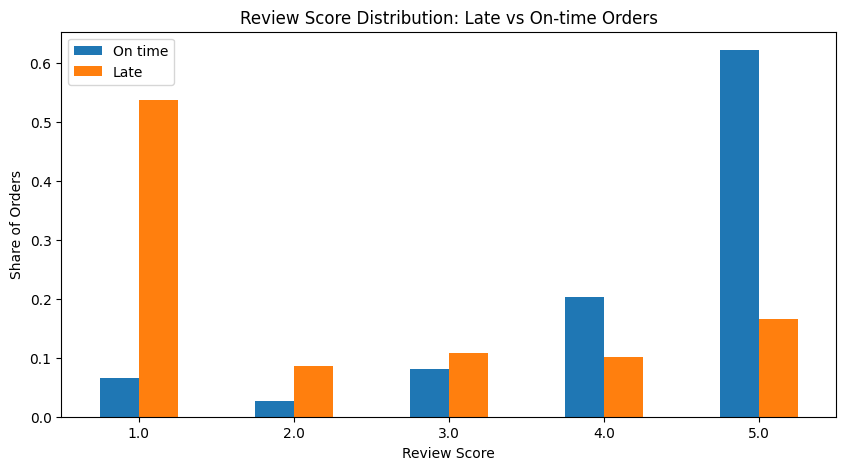

In [25]:
ct.T.plot(kind='bar', figsize=(10, 5))
plt.title('Review Score Distribution: Late vs On-time Orders')
plt.xlabel('Review Score')
plt.ylabel('Share of Orders')
plt.legend(['On time', 'Late'])
plt.xticks(rotation=0)
plt.show()

In [26]:
df_r = df.dropna(subset=['review_score']).copy()
df_r['low_score'] = df_r['review_score'] <= 2


bins = [-200, -10, -5, 0, 3, 7, 14, 30, 200]
labels = ['10+ early', '5-9 early', '0-4 early',
          '1-3 late', '4-7 late', '8-14 late', '15-30 late', '31+ late']

df_r['delay_group'] = pd.cut(df_r['delay_days'], bins=bins, labels=labels)

dose = df_r.groupby('delay_group', observed=True).agg(
    n_orders=('order_id', 'count'),
    mean_score=('review_score', 'mean'),
    low_score_rate=('low_score', 'mean')
)
dose

,n_orders,mean_score,low_score_rate
delay_group,,,
10+ early,61523,4.323277,0.088926
5-9 early,20032,4.255591,0.096046
0-4 early,7888,4.120943,0.113463
1-3 late,1852,3.291037,0.321274
4-7 late,1748,2.104691,0.676201
8-14 late,1446,1.670816,0.801521
15-30 late,1006,1.613320,0.818091
31+ late,329,2.057751,0.677812


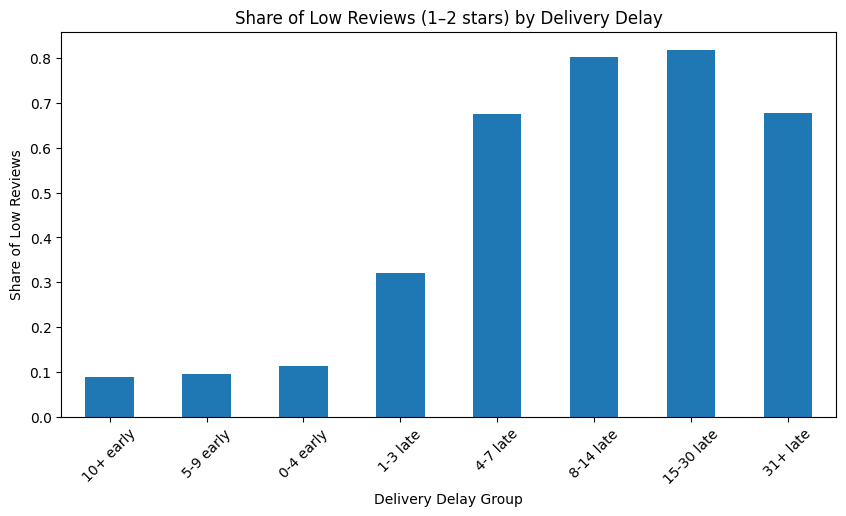

In [27]:
dose['low_score_rate'].plot(kind='bar', figsize=(10, 5))
plt.title('Share of Low Reviews (1–2 stars) by Delivery Delay')
plt.xlabel('Delivery Delay Group')
plt.ylabel('Share of Low Reviews')
plt.xticks(rotation=45)
plt.show()

In [28]:
dose['se'] = np.sqrt(dose['low_score_rate'] * (1 - dose['low_score_rate']) / dose['n_orders'])
dose['ci_low'] = dose['low_score_rate'] - 1.96 * dose['se']
dose['ci_high'] = dose['low_score_rate'] + 1.96 * dose['se']

dose[['n_orders', 'low_score_rate', 'ci_low', 'ci_high']].round(3)

,n_orders,low_score_rate,ci_low,ci_high
delay_group,,,,
10+ early,61523,0.089,0.087,0.091
5-9 early,20032,0.096,0.092,0.100
0-4 early,7888,0.113,0.106,0.120
1-3 late,1852,0.321,0.300,0.343
4-7 late,1748,0.676,0.654,0.698
8-14 late,1446,0.802,0.781,0.822
15-30 late,1006,0.818,0.794,0.842
31+ late,329,0.678,0.627,0.728


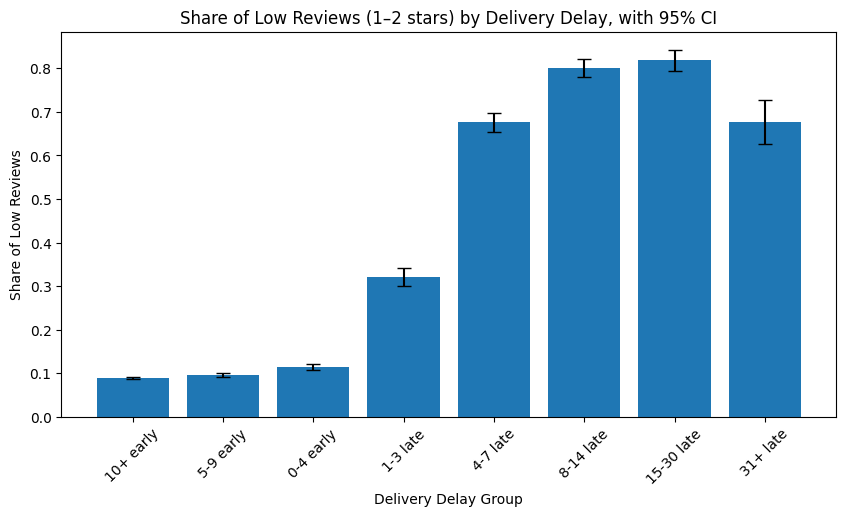

In [29]:
plt.figure(figsize=(10, 5))
plt.bar(dose.index.astype(str), dose['low_score_rate'],
        yerr=1.96 * dose['se'], capsize=5)
plt.title('Share of Low Reviews (1–2 stars) by Delivery Delay, with 95% CI')
plt.xlabel('Delivery Delay Group')
plt.ylabel('Share of Low Reviews')
plt.xticks(rotation=45)
plt.show()

## Key findings: delivery delay and customer satisfaction
- On-time orders: mean review score 4.29; late orders: 2.27.
- 54% of late orders receive 1 star, compared with 7% of on-time orders.
- The biggest jump happens when the promised date is missed:
  low-review share rises from 11% (0–4 days early) to 32% (1–3 days late).
- Arriving very early adds little extra satisfaction (9% vs 11%).
- Low-review share increases with delay length, up to ~82% for 15–30 days late.
- Open question: the 31+ days late group shows a lower share (68%);
  the 95% CIs do not overlap with the 15–30 group, so this is unlikely to be noise.
  One possible explanation, not tested here, is reviews written before delivery.

## Stage 3: Feature engineering

In [30]:
items = pd.read_csv('olist_order_items_dataset.csv')

print(items.shape)
items.head()

(112650, 7)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [31]:
items_per_order = items.groupby('order_id').size()
items_per_order.value_counts().sort_index()

1     88863
2      7516
3      1322
4       505
5       204
6       198
7        22
8         8
9         3
10        8
11        4
12        5
13        1
14        2
15        2
20        2
21        1
Name: count, dtype: int64

In [32]:
items_agg = items.groupby('order_id').agg(
    n_items=('order_item_id', 'count'),
    total_price=('price', 'sum'),
    total_freight=('freight_value', 'sum'),
    n_sellers=('seller_id', 'nunique')
).reset_index()

items_agg['freight_ratio'] = items_agg['total_freight'] / items_agg['total_price']

items_agg.head()

,order_id,n_items,total_price,total_freight,n_sellers,freight_ratio
0,00010242fe8c5a6d1ba2dd792cb16214,1,58.90,13.29,1,0.225637
1,00018f77f2f0320c557190d7a144bdd3,1,239.90,19.93,1,0.083076
2,000229ec398224ef6ca0657da4fc703e,1,199.00,17.87,1,0.089799
3,00024acbcdf0a6daa1e931b038114c75,1,12.99,12.79,1,0.984604
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,199.90,18.14,1,0.090745


In [33]:
df = df.merge(items_agg, on='order_id', how='left')

print(df.shape)
df[['n_items', 'total_price', 'total_freight', 'freight_ratio', 'n_sellers']].describe()

(96470, 17)


,n_items,total_price,total_freight,freight_ratio,n_sellers
count,96470.000000,96470.000000,96470.000000,96470.000000,96470.000000
mean,1.142210,137.040001,22.785798,0.308386,1.013901
std,0.538824,209.052608,21.559959,0.311618,0.123542
min,1.000000,0.850000,0.000000,0.000000,1.000000
25%,1.000000,45.900000,13.850000,0.132017,1.000000
50%,1.000000,86.500000,17.170000,0.224374,1.000000
75%,1.000000,149.900000,24.020000,0.380567,1.000000
max,21.000000,13440.000000,1794.960000,21.447059,5.000000


In [34]:
df.sort_values('freight_ratio', ascending=False)[
    ['total_price', 'total_freight', 'n_items', 'freight_ratio']
].head(10)

,total_price,total_freight,n_items,freight_ratio
68968,0.85,18.23,1,21.447059
80790,0.85,18.23,1,21.447059
81879,9.18,54.69,3,5.957516
14709,5.95,34.15,1,5.739496
71965,6.99,37.90,1,5.422031
81029,14.00,74.08,2,5.291429
25530,17.50,91.15,5,5.208571
86187,31.80,164.37,21,5.168868
84289,3.00,15.23,1,5.076667
54839,4.90,24.84,1,5.069388


In [35]:
df['log_price'] = np.log(df['total_price'])
df['log_freight'] = np.log1p(df['total_freight'])

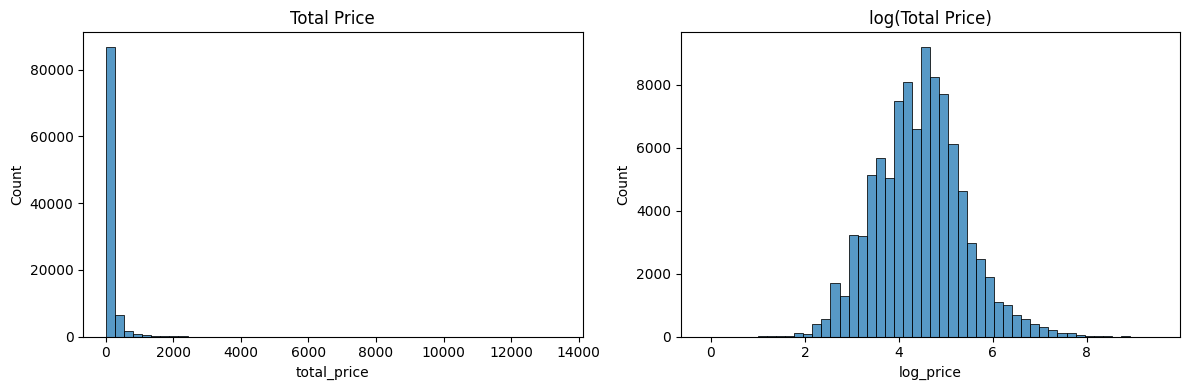

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df['total_price'], bins=50, ax=axes[0])
axes[0].set_title('Total Price')

sns.histplot(df['log_price'], bins=50, ax=axes[1])
axes[1].set_title('log(Total Price)')

plt.tight_layout()
plt.show()

In [37]:
customers = pd.read_csv('olist_customers_dataset.csv')
sellers = pd.read_csv('olist_sellers_dataset.csv')

print(customers.shape, sellers.shape)
print('Təkrarlanan customer_id:', customers['customer_id'].duplicated().sum())
print('Təkrarlanan seller_id:', sellers['seller_id'].duplicated().sum())

(99441, 5) (3095, 4)
Təkrarlanan customer_id: 0
Təkrarlanan seller_id: 0


In [38]:
df = df.merge(
    customers[['customer_id', 'customer_zip_code_prefix', 'customer_state']],
    on='customer_id',
    how='left'
)

In [39]:
order_seller = items.groupby('order_id')['seller_id'].first().reset_index()

order_seller = order_seller.merge(
    sellers[['seller_id', 'seller_zip_code_prefix', 'seller_state']],
    on='seller_id',
    how='left'
)

df = df.merge(order_seller, on='order_id', how='left')

df['same_state'] = df['customer_state'] == df['seller_state']

print(df.shape)

(96470, 25)


In [40]:
df.groupby('same_state')[['is_late', 'delay_days']].mean()

,is_late,delay_days
same_state,,
False,0.080477,-12.742686
True,0.045042,-10.332959


In [41]:
df.groupby('customer_state').agg(
    n_orders=('order_id', 'count'),
    late_rate=('is_late', 'mean')
).sort_values('late_rate', ascending=False).head(10)

,n_orders,late_rate
customer_state,,
AL,397,0.214106
MA,717,0.174338
SE,335,0.152239
PI,476,0.138655
CE,1279,0.137608
RR,41,0.121951
BA,3256,0.121622
RJ,12350,0.121053
PA,946,0.112051


In [42]:
sellers['seller_state'].value_counts(normalize=True).head()

seller_state
SP    0.597415
PR    0.112763
MG    0.078837
SC    0.061389
RJ    0.055250
Name: proportion, dtype: float64

In [43]:

geo = pd.read_csv('olist_geolocation_dataset.csv')
geo = geo[
    geo['geolocation_lat'].between(-33.75, 5.27) &
    geo['geolocation_lng'].between(-73.99, -34.79)
]


geo_agg = geo.groupby('geolocation_zip_code_prefix').agg(
    lat=('geolocation_lat', 'mean'),
    lng=('geolocation_lng', 'mean')
).reset_index()

customer_geo = geo_agg.rename(columns={
    'geolocation_zip_code_prefix': 'customer_zip_code_prefix',
    'lat': 'customer_lat', 'lng': 'customer_lng'
})
seller_geo = geo_agg.rename(columns={
    'geolocation_zip_code_prefix': 'seller_zip_code_prefix',
    'lat': 'seller_lat', 'lng': 'seller_lng'
})
df = df.merge(customer_geo, on='customer_zip_code_prefix', how='left')
df = df.merge(seller_geo, on='seller_zip_code_prefix', how='left')

def haversine(lat1, lon1, lat2, lon2):
    R = 6371  # Earth radius (km)
    lat1, lon1 = np.radians(lat1), np.radians(lon1)
    lat2, lon2 = np.radians(lat2), np.radians(lon2)
    a = np.sin((lat2 - lat1) / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

df['distance_km'] = haversine(df['customer_lat'], df['customer_lng'],
                              df['seller_lat'], df['seller_lng'])

# 5. Checks
print(df.shape)
print('Missing distance:', df['distance_km'].isnull().sum())
print(df[['customer_lat', 'customer_lng', 'seller_lat', 'seller_lng']].describe().loc[['min', 'max']])
df['distance_km'].describe()

(96470, 30)
Missing distance: 479
     customer_lat  customer_lng  seller_lat  seller_lng
min    -33.689948    -72.668881  -32.079231  -63.893565
max      3.842508    -34.799347   -2.501242  -34.855616


count    95991.000000
mean       600.382038
std        592.317573
min          0.000000
25%        185.928815
50%        433.814287
75%        798.282592
max       3399.190906
Name: distance_km, dtype: float64

In [44]:
df['distance_group'] = pd.qcut(df['distance_km'], q=5)

df.groupby('distance_group', observed=True)['is_late'].mean()

distance_group
(-0.001, 116.047]      0.045367
(116.047, 347.943]     0.057766
(347.943, 529.692]     0.066101
(529.692, 876.506]     0.072195
(876.506, 3399.191]    0.096573
Name: is_late, dtype: float64

In [45]:
products = pd.read_csv('olist_products_dataset.csv')
translation = pd.read_csv('product_category_name_translation.csv')

print(products.shape)
products.isnull().sum()

(32951, 9)


product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

In [46]:
products = products.merge(translation, on='product_category_name', how='left')

items_prod = items.merge(
    products[['product_id', 'product_category_name_english', 'product_weight_g']],
    on='product_id',
    how='left'
)

order_prod = items_prod.groupby('order_id').agg(
    category=('product_category_name_english', 'first'),
    total_weight_g=('product_weight_g', 'sum')
).reset_index()

df = df.merge(order_prod, on='order_id', how='left')
df['log_weight'] = np.log1p(df['total_weight_g'])

print(df.shape)
print('Kateqoriyası boş:', df['category'].isnull().sum())
print('Unikal kateqoriya sayı:', df['category'].nunique())

(96470, 34)
Kateqoriyası boş: 1351
Unikal kateqoriya sayı: 71


In [47]:
df.groupby('category').agg(
    n_orders=('order_id', 'count'),
    late_rate=('is_late', 'mean'),
    mean_score=('review_score', 'mean')
).query('n_orders >= 500').sort_values('mean_score').head(10)

,n_orders,late_rate,mean_score
category,,,
office_furniture,1246,0.081059,3.650485
bed_bath_table,9171,0.075128,4.009806
telephony,4076,0.071394,4.056022
furniture_decor,6213,0.071785,4.071834
computers_accessories,6501,0.064144,4.083308
baby,2763,0.081795,4.121489
watches_gifts,5470,0.074223,4.126703
electronics,2507,0.076586,4.128617
construction_tools_construction,728,0.074176,4.132780


In [49]:
df['category'] = df['category'].fillna('unknown')

counts = df['category'].value_counts()
keep = counts[counts >= 1000].index
df['category_grouped'] = df['category'].where(df['category'].isin(keep), 'other')

print('Kateqoriya sayı:', df['category_grouped'].nunique())
df['category_grouped'].value_counts()

Kateqoriya sayı: 23


category_grouped
other                       10019
bed_bath_table               9171
health_beauty                8608
sports_leisure               7492
computers_accessories        6501
furniture_decor              6213
housewares                   5695
watches_gifts                5470
telephony                    4076
auto                         3793
toys                         3779
cool_stuff                   3531
garden_tools                 3414
perfumery                    3075
baby                         2763
electronics                  2507
stationery                   2248
fashion_bags_accessories     1813
pet_shop                     1683
unknown                      1351
office_furniture             1246
consoles_games               1014
luggage_accessories          1008
Name: count, dtype: int64

In [50]:
df.to_csv('olist_model_data.csv', index=False)
print('Saved:', df.shape)

Saved: (96470, 35)
